# 01 · Data exploration

Public FitRec / Endomondo running workouts (see `docs/data_card.md`). Goal: understand the data, check its quality and write down its limitations **before** modelling.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from athleteiq.config import data_dir
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
D = data_dir(); print('data:', D.relative_to(D.parents[1]))

data: data/processed


In [2]:
s = pd.read_parquet(D / 'sessions.parquet')
print(f'{len(s):,} workouts · {s.user_id.nunique()} athletes · {s.start_time.min():%Y-%m-%d} to {s.start_time.max():%Y-%m-%d}')
s[['duration_min','distance_km','avg_speed_kmh','elev_gain_m','hr_mean','hr_max','trimp']].describe().round(1)

40,186 workouts · 761 athletes · 2007-02-07 to 2016-01-01


,duration_min,distance_km,avg_speed_kmh,elev_gain_m,hr_mean,hr_max,trimp
count,40186.0,40186.0,40186.0,40186.0,40186.0,40186.0,40186.0
mean,68.7,12.2,11.0,110.3,149.5,166.6,233.2
std,36.5,6.1,1.8,114.8,12.1,12.8,129.8
min,8.5,0.8,1.8,0.0,117.2,126.1,15.3
25%,46.0,8.4,9.8,45.8,141.3,158.3,152.6
50%,60.5,10.7,11.0,81.1,149.6,167.1,205.4
75%,81.1,14.7,12.2,135.4,157.6,175.5,278.2
max,299.8,54.3,23.8,3200.5,191.5,200.0,1303.4


## How much history does each athlete have?
Personal baselines need history, so this decides what is possible per athlete.

count    761.0
mean      52.8
std       67.0
min        1.0
25%        9.0
50%       28.0
75%       71.0
max      673.0
dtype: float64
athletes with >=10 sessions: 569 | >=50: 264


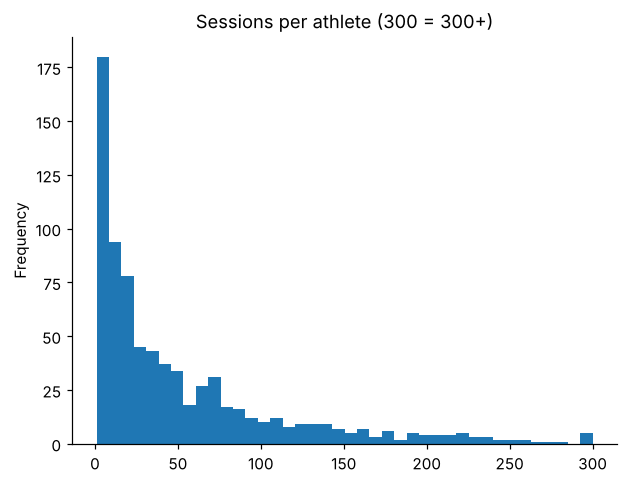

In [3]:
n = s.groupby('user_id').size()
print(n.describe().round(1))
print('athletes with >=10 sessions:', (n>=10).sum(), '| >=50:', (n>=50).sum())
n.clip(upper=300).plot.hist(bins=40, title='Sessions per athlete (300 = 300+)');

## Recording is sparse
Gaps between recorded runs are long and irregular, so 'days without a run' often means 'not recorded with HR', not rest. Training loads are therefore lower bounds.

count    39425.0
mean        12.1
std         38.8
min          0.0
25%          2.0
50%          4.0
75%          8.8
90%         21.1
99%        161.7
max       1740.1
Name: days_since_last, dtype: float64


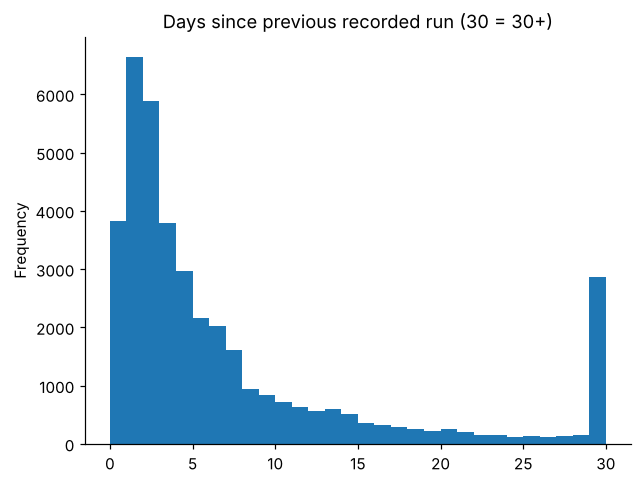

In [4]:
gap = s.days_since_last.dropna()
print(gap.describe(percentiles=[.25,.5,.75,.9,.99]).round(1))
gap.clip(upper=30).plot.hist(bins=30, title='Days since previous recorded run (30 = 30+)');

## Data quality checks
The packager already smoothed the series (7-point moving average) and dropped implausible workouts, so spikes are rare by construction. Our checks still catch recording gaps and frozen HR.

In [5]:
print(s.quality_label.value_counts())
s[['q_gaps','q_max_gap_s','q_hr_flatline_s','q_gps_jumps','quality_score']].describe().round(2)

quality_label
good     38361
check     1759
poor        66
Name: count, dtype: int64


,q_gaps,q_max_gap_s,q_hr_flatline_s,q_gps_jumps,quality_score
count,40186.00,40186.00,40186.00,40186.00,40186.00
mean,0.43,48.36,32.96,0.00,0.97
std,1.15,59.75,18.08,0.05,0.06
min,0.00,2.00,2.00,0.00,0.40
25%,0.00,14.00,22.00,0.00,1.00
50%,0.00,21.00,29.00,0.00,1.00
75%,0.00,55.00,40.00,0.00,1.00
max,37.00,300.00,312.00,6.00,1.00


## Selection bias to remember
The packager kept only workouts with mean HR >= 120 bpm and max <= 200 bpm, so very easy runs are missing. The model is only valid inside this range.

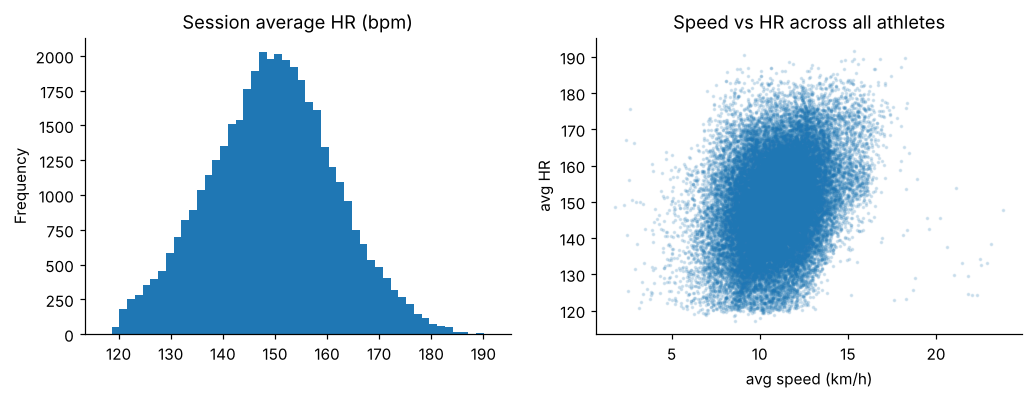

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
s.hr_mean.plot.hist(bins=50, ax=ax[0], title='Session average HR (bpm)')
ax[1].scatter(s.avg_speed_kmh, s.hr_mean, s=2, alpha=.15)
ax[1].set(xlabel='avg speed (km/h)', ylabel='avg HR', title='Speed vs HR across all athletes');

Across athletes the speed–HR cloud is wide: fitness differs. **Within** an athlete the relationship is much tighter, which is why personal history features matter.

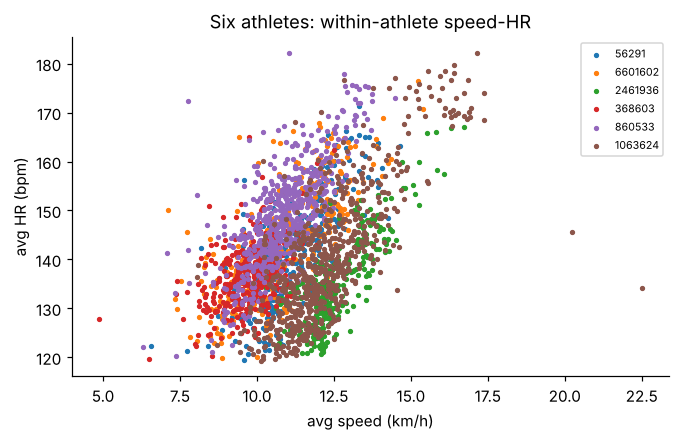

In [7]:
top = s.groupby('user_id').size().sort_values().index[-6:]
fig, ax = plt.subplots(figsize=(7, 4))
for u in top:
    g = s[s.user_id == u]; ax.scatter(g.avg_speed_kmh, g.hr_mean, s=6, label=str(u))
ax.set(xlabel='avg speed (km/h)', ylabel='avg HR (bpm)', title='Six athletes: within-athlete speed-HR'); ax.legend(fontsize=7);

In [8]:
w = s.groupby('user_id').apply(lambda g: g[['avg_speed_kmh','hr_mean']].corr().iloc[0,1] if len(g)>=20 else np.nan, include_groups=False)
print('median within-athlete corr(speed, HR):', round(w.median(), 2), '| pooled corr:', round(s[['avg_speed_kmh','hr_mean']].corr().iloc[0,1], 2))

median within-athlete corr(speed, HR): 0.6 | pooled corr: 0.31


## Intensity and load
Zones are % of an **estimated** HRmax (highest HR seen so far); there is no lab test.

In [9]:
z = s[[f'z{k}_min' for k in range(1,6)]].sum(); (z/z.sum()*100).round(1).rename('share of time %')

z1_min     1.5
z2_min    12.5
z3_min    38.0
z4_min    37.6
z5_min    10.4
Name: share of time %, dtype: float64

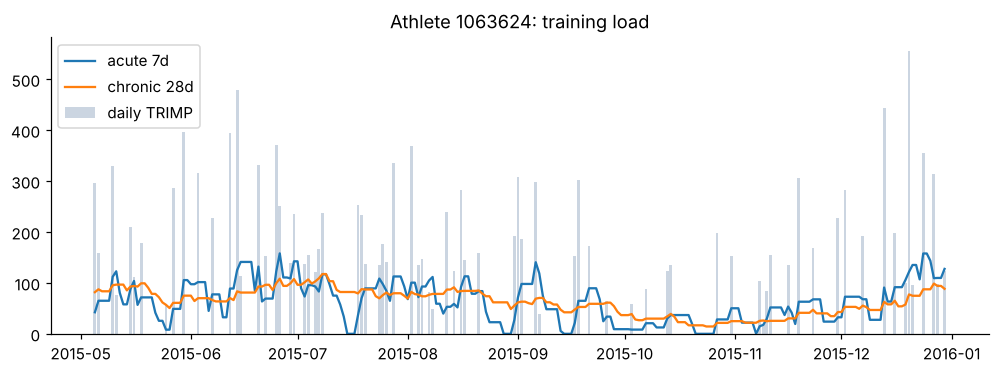

In [10]:
dl = pd.read_parquet(D / 'daily_load.parquet')
u = n.idxmax(); g = dl[dl.user_id==u].tail(240)
fig, ax = plt.subplots(figsize=(11, 3.5)); ax.bar(g.date, g.load, color='#CBD5E1', label='daily TRIMP')
ax.plot(g.date, g.acute, label='acute 7d'); ax.plot(g.date, g.chronic, label='chronic 28d'); ax.legend(); ax.set_title(f'Athlete {u}: training load');

## Limitations written down before modelling
- Running only; no sleep, HRV, age, sex or lab HRmax → no validated readiness score is possible.
- Series were resampled to 500 points and smoothed by the packager.
- Mean HR ≥ 120 bpm filter removes easy runs (selection bias).
- Workouts not recorded with HR are invisible → load is a lower bound.
- The RECOVERY / STEADY / INTENSIVE label is HR-derived → never used as a feature.